# Analysis of GC behavior

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import scipy
from scipy.cluster.hierarchy import linkage, leaves_list
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import sklearn
from itertools import combinations
import colorcet as cc

from sklearn.covariance import MinCovDet
from scipy.stats import chi2
import math
import networkx as nx

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

import os
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/')
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

mm_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()
mm_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()

hg_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()
hg_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()

from scipy.sparse.csgraph import connected_components


/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
import scib
from scib.metrics import *
from analysis_helpers import *

In [4]:
df_full = pd.read_csv('../results/spreadsheets/metric_values_v11.csv', index_col=0)
df_full['Dataset'] = df_full['Dataset'].replace({
    'nph_cerebellum': 'nhp_cerebellum',
    'nph_liver': 'nhp_liver'
})
pivoted_df = df_full.pivot(index=['Dataset', 'Integration'], columns='Metric', values='Value')

runs = pd.read_csv('../results/spreadsheets/all_integrations.csv')

## LIGER integration of the human pancreas data

In [21]:
adata = sc.read('../data/human_pancreas.h5ad')
adata

AnnData object with n_obs × n_vars = 16382 × 19093
    obs: 'tech', 'celltype', 'size_factors'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'seurat_v3_highly_variable', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'log1p', 'neighbors', 'pca', 'species', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'orig_counts'
    obsp: 'connectivities', 'distances'

In [58]:
d = runs[runs.name.str.contains('human_pancreas') & runs.name.str.contains('liger')].iloc[0]['workdir']
adata_int = sc.read(f"{d}/save_dir/adata.h5ad")
batch_col = adata_int.obs.columns[0]
celltype_col = adata_int.obs.columns[-11]

if adata_int.X is None:
    adata_int = ad.AnnData(
        X=adata.X,
        obs=adata_int.obs,
        var=adata.var,
        uns=adata_int.uns,
        obsm=adata_int.obsm,
        varm=adata_int.varm,
        obsp=adata_int.obsp,
        varp=adata.varp,
        layers=adata.layers,
)

adata_int

AnnData object with n_obs × n_vars = 16382 × 19093
    obs: 'tech', 'celltype', 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'seurat_v3_highly_variable', 'dispersions', 'dispersions_norm'
    uns: 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0', 'neighbors'
    obsm: 'X_integration', 'X_umap'
    layers: 'counts', 'orig_counts'
    obsp: 'connectivities', 'distances'

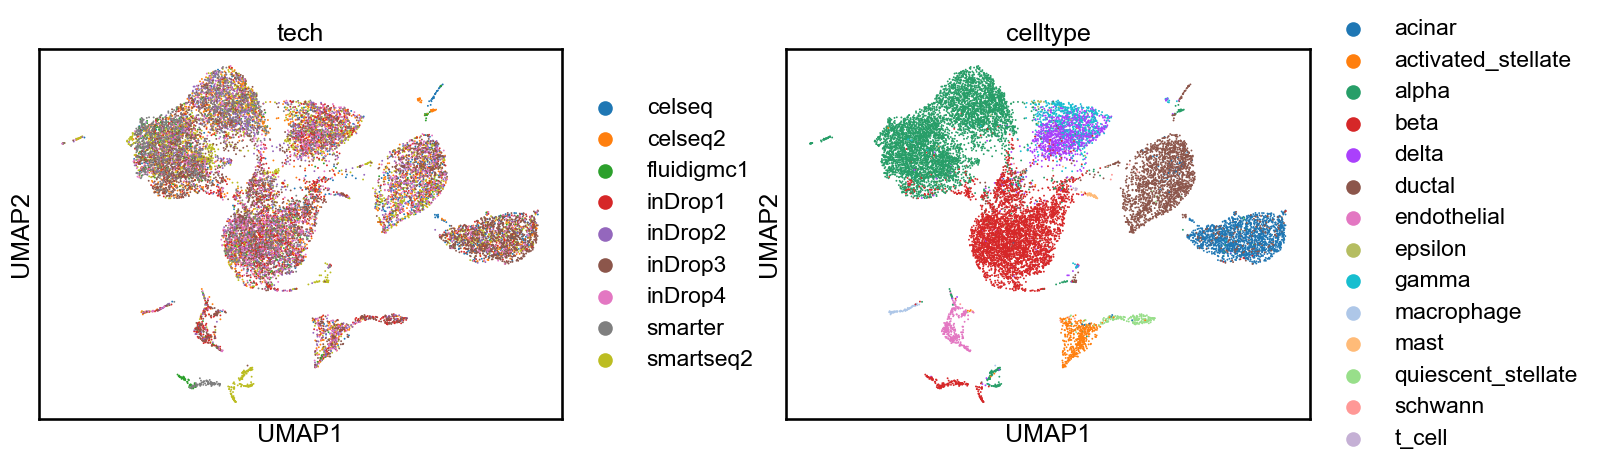

In [59]:
sc.pl.umap(adata_int, color=[batch_col, celltype_col], ncols=2, wspace=0.3)

In [72]:
clust_res = []
tabs = {}

adata_int.obs['majority'] = False
for label in adata_int.obs[celltype_col].cat.categories:
    adata_sub = adata_int[adata_int.obs[celltype_col].isin([label])]
    _, labels = connected_components(
        adata_sub.obsp["connectivities"], connection="strong"
    )
    labels = pd.Series(labels, index=adata_sub.obs.index)
    tab = labels.value_counts()
    tabs[label] = tab
    clust_res.append(tab.max() / sum(tab))
    adata_int.obs.loc[labels.index[labels == tab.index[0]],  'majority'] = True
    
#     if label == 'alpha': break

np.mean(clust_res)

np.float64(0.8969331829858149)

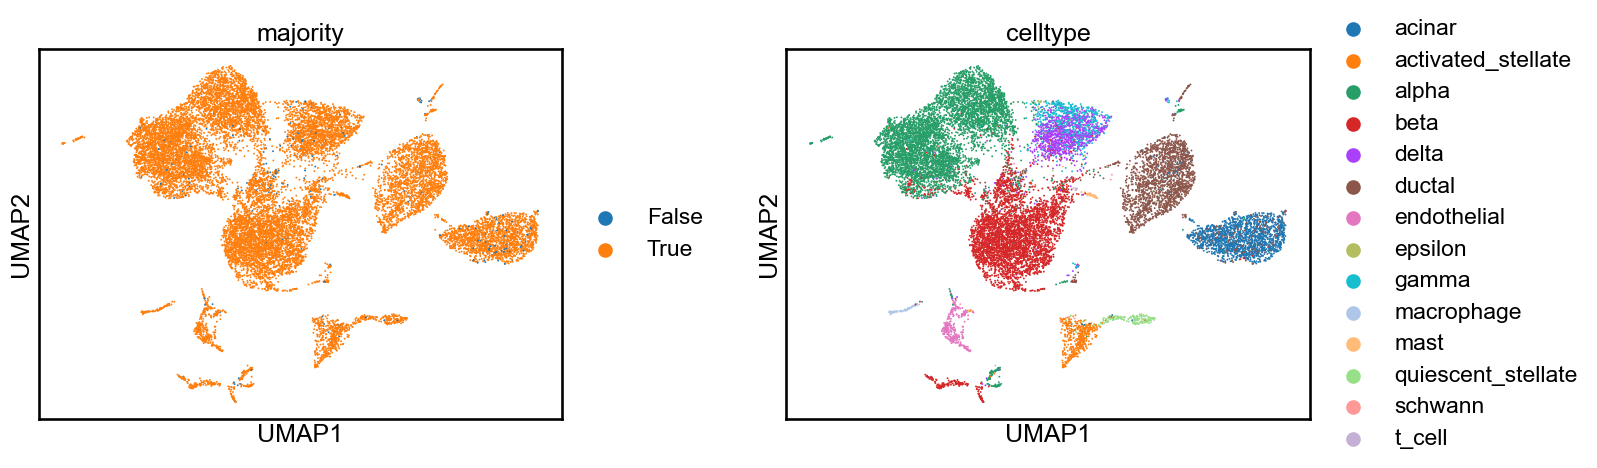

In [76]:
sc.pl.umap(adata_int, color=['majority', celltype_col], ncols=2, wspace=0.3)

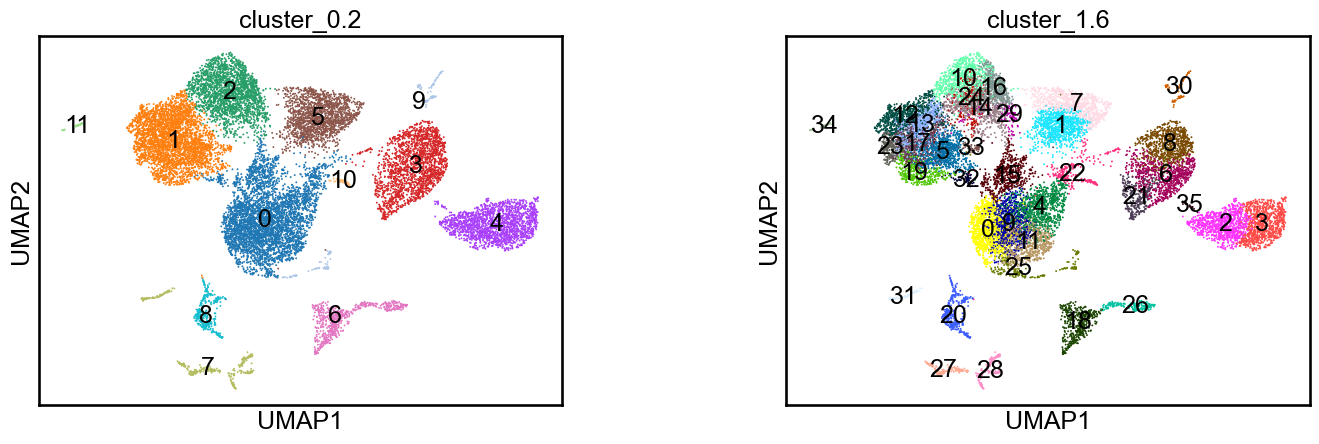

In [138]:
sc.pl.umap(adata_int, color=['cluster_0.2','cluster_1.6'], legend_loc='on data', ncols=2, wspace=0.3)

In [108]:
adata_sub.obs.index.get_loc('12th-C14_S190')

636

In [104]:
adata_int[adata_int.obs['cluster_1.6'] == '0'].obs.index

Index(['D28-5_76', 'D30-6_83', 'D31-3_22', 'D31-7_74', '4th-C26_S50',
       'D101_14', 'D102_7', 'D102_11', 'D102_18', 'D102_25',
       ...
       'Sample_911', 'Sample_915', 'Sample_916', 'Sample_917', 'Sample_918',
       'Sample_919', 'Sample_932', 'Sample_945', 'Sample_946', 'Sample_947'],
      dtype='object', name='barcode', length=955)

In [106]:
adata_int[adata_int.obs['cluster_1.6'] == '27'].obs.index

Index(['4th-C89_S83', '6th-C23_S38', '10th_C23_S98', '10th_C37_S49',
       '11th-C41_S60', '12th-C14_S190', '12th-C15_S183', '12th-C25_S185',
       '12th-C42_S159', '12th-C60_S176',
       ...
       'Sample_934', 'Sample_935', 'Sample_936', 'Sample_937', 'Sample_938',
       'Sample_939', 'Sample_940', 'Sample_941', 'Sample_942', 'Sample_943'],
      dtype='object', name='barcode', length=136)

In [95]:
adata_int.obsp['connectivities'][3616, 1200]

np.float32(0.0)

In [100]:
adata_sub = adata_int[adata_int.obs[celltype_col].isin(['beta'])]

In [111]:
G = nx.from_numpy_array(adata_sub.obsp['connectivities'], create_using=nx.DiGraph)

In [112]:
path = nx.shortest_path(G, source=4131, target=636, weight='weight')

In [158]:
path = path[:11]

In [159]:
cell_path = adata_sub.obs.iloc[path].index

In [160]:
indices = adata_int.obs_names.get_indexer(cell_path)
path_coords = adata_int.obsm['X_umap'][indices]

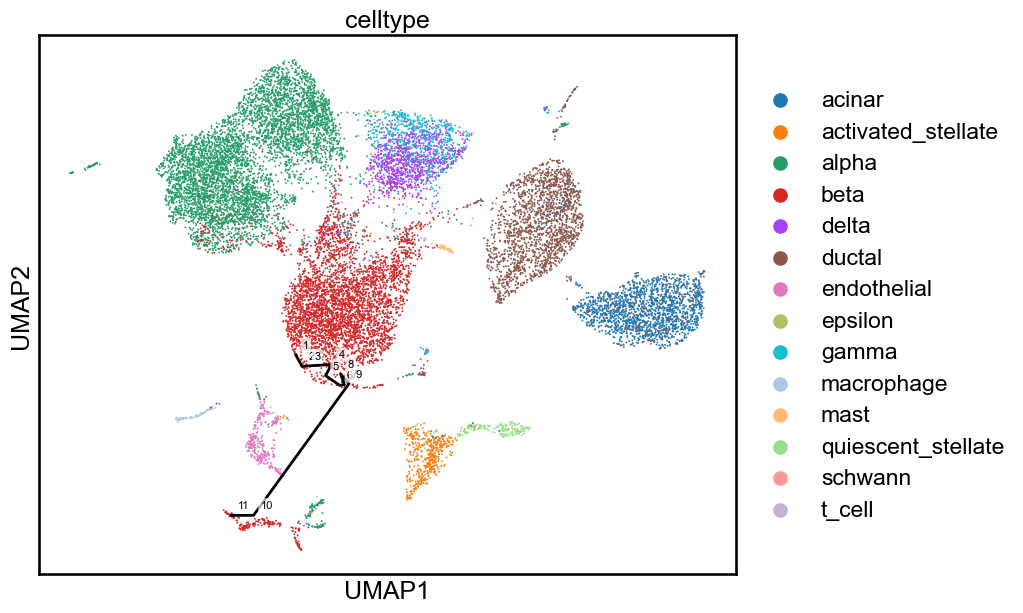

In [162]:
with plt.rc_context({'figure.figsize': (9, 7)}):
    ax = sc.pl.umap(adata_int, show=False, color=celltype_col) # or your preferred coloring

    # Plot the path as a line
    # path_coords[:, 0] are X coordinates, path_coords[:, 1] are Y
    ax.plot(path_coords[:, 0], path_coords[:, 1], 
            color='black', 
            linewidth=2, 
            linestyle='-', 
            label='Trajectory',
            zorder=10) # zorder ensures the line stays on top of the dots

    # Optional: Add arrows to show direction
    for i, (x, y) in enumerate(path_coords):
        ax.annotate(
            str(i + 1),
            xy=(x, y),              # The actual cell location
            xytext=(5, 5),          # Offset in points (5 right, 5 up)
            textcoords='offset points', 
            fontsize=8,
            fontweight='bold',
            zorder=11,
            bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.7)
        )

    plt.show()

In [149]:
d1 = adata_int[adata_int.obs['cluster_1.6'] == '25'].obsm[EMB_KEY].mean(0)  # Closest beta
d2 = adata_int[adata_int.obs['cluster_1.6'] == '27'].obsm[EMB_KEY].mean(0)  # Aberrant beta
d3 = adata_int[adata_int.obs['cluster_1.6'] == '20'].obsm[EMB_KEY].mean(0)  # Other cluster
d4 = adata_int[adata_int.obs['cluster_1.6'] == '26'].obsm[EMB_KEY].mean(0)  # Other cluster
d5 = adata_int[adata_int.obs['cluster_1.6'] == '0'].obsm[EMB_KEY].mean(0)  # second-closest beta
# d6 = adata_int[adata_int.obs['cluster_1.6'] == '11'].obsm[EMB_KEY].mean(0)  # third-closest beta

In [150]:
np.linalg.norm(d1 - d2), np.linalg.norm(d1 - d3), np.linalg.norm(d1 - d4), np.linalg.norm(d1 - d5), np.linalg.norm(d1- d6)

(np.float64(0.03641549680483368),
 np.float64(0.052925988038082614),
 np.float64(0.05072880457631997),
 np.float64(0.02743521803225388),
 np.float64(0.027294605879603175))

In [137]:
adata_int[adata_int.obs['cluster_1.6'] == '20'].obsm[EMB_KEY].mean(0)

array([0.00275955, 0.00033009, 0.00021995, 0.00092215, 0.00104741,
       0.00079224, 0.00196629, 0.00592231, 0.00030652, 0.00067776,
       0.00152578, 0.00040602, 0.000773  , 0.00030185, 0.00350749,
       0.00428697, 0.00086494, 0.04410655, 0.00439075, 0.00399305])

## PCA (unintegrated) human pancreas

This part is used for the supplemental figure on GC behavior

In [163]:
d = runs[runs.name.str.contains('human_pancreas') & runs.name.str.contains('_pca')].iloc[0]['workdir']
adata_int = sc.read(f"{d}/save_dir/adata.h5ad")
batch_col = adata_int.obs.columns[0]
celltype_col = adata_int.obs.columns[-11]

if adata_int.X is None:
    adata_int = ad.AnnData(
        X=adata.X,
        obs=adata_int.obs,
        var=adata.var,
        uns=adata_int.uns,
        obsm=adata_int.obsm,
        varm=adata_int.varm,
        obsp=adata_int.obsp,
        varp=adata.varp,
        layers=adata.layers,
)

adata_int

AnnData object with n_obs × n_vars = 16382 × 19093
    obs: 'tech', 'celltype', 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'seurat_v3_highly_variable', 'dispersions', 'dispersions_norm'
    uns: 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0', 'neighbors'
    obsm: 'X_integration', 'X_umap'
    layers: 'counts', 'orig_counts'
    obsp: 'connectivities', 'distances'

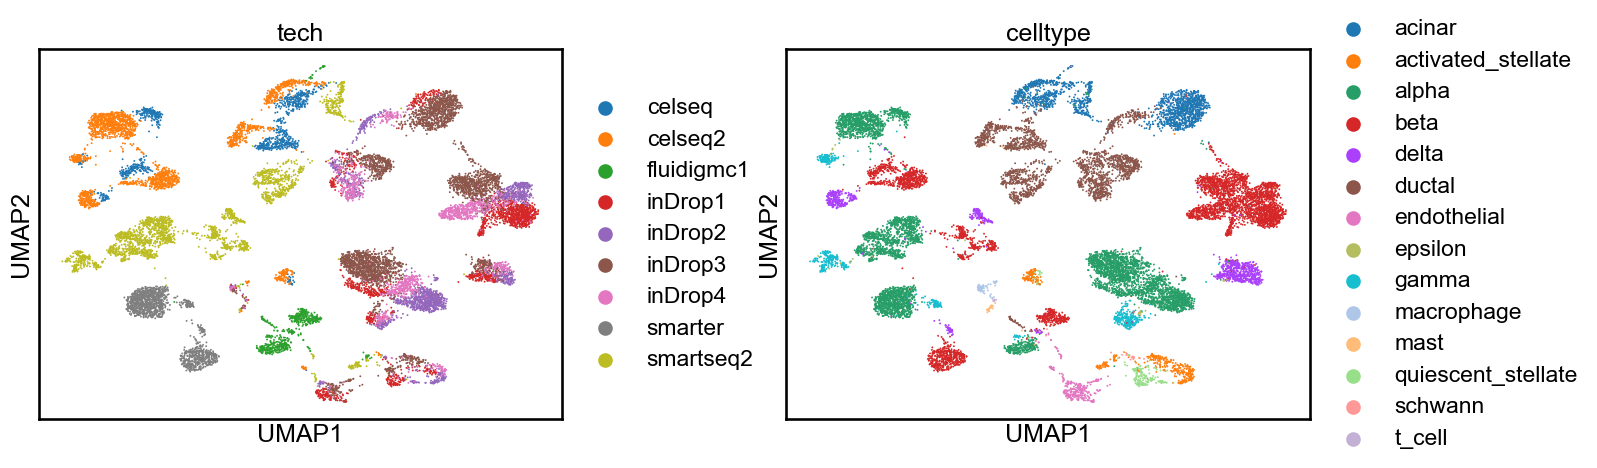

In [164]:
sc.pl.umap(adata_int, color=[batch_col, celltype_col], ncols=2, wspace=0.3)

In [387]:
adata_sub.obsp['connectivities'], adata_sub.obsp['distances']

(<Compressed Sparse Row sparse matrix of dtype 'float32'
 	with 88942 stored elements and shape (4169, 4169)>,
 <Compressed Sparse Row sparse matrix of dtype 'float32'
 	with 65785 stored elements and shape (4169, 4169)>)

In [418]:
clust_res = []
tabs = {}

adata_int.obs['majority'] = False
for label in adata_int.obs[celltype_col].cat.categories:
    adata_sub = adata_int[adata_int.obs[celltype_col].isin([label])]
    _, labels = connected_components(
        adata_sub.obsp["connectivities"], connection="strong"
    )
    labels = pd.Series(labels, index=adata_sub.obs.index)
    tab = labels.value_counts()
    tabs[label] = tab
    clust_res.append(tab.max() / sum(tab))
    adata_int.obs.loc[labels.index[labels == tab.index[0]],  'majority'] = True
    
#     if label == 'alpha': break

np.mean(clust_res)

np.float64(0.9540549055282327)

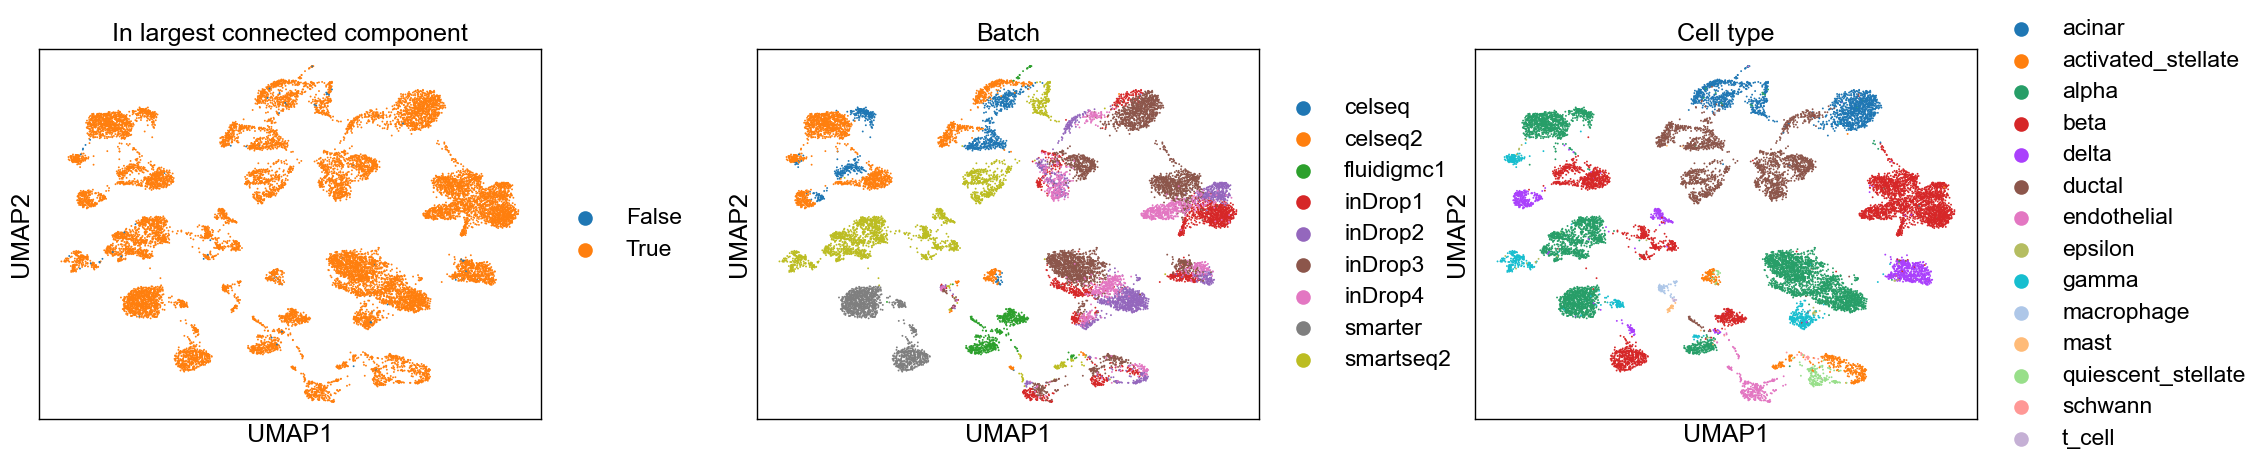

In [419]:
axes = sc.pl.umap(
    adata_int, 
    color=['majority', batch_col, celltype_col], 
    ncols=3, 
    wspace=0.3, 
    show=False,
    title=['In largest connected component', 'Batch', 'Cell type']
)

# 2. Define your desired thickness
frame_thickness = 1.0 

# 3. Iterate through each subplot and its spines
for ax in axes:
    for spine in ax.spines.values():
        spine.set_linewidth(frame_thickness)
        # Optional: ensure the color matches if it looks too grey
        # spine.set_edgecolor('black') 

# 4. Show the final result
plt.show()

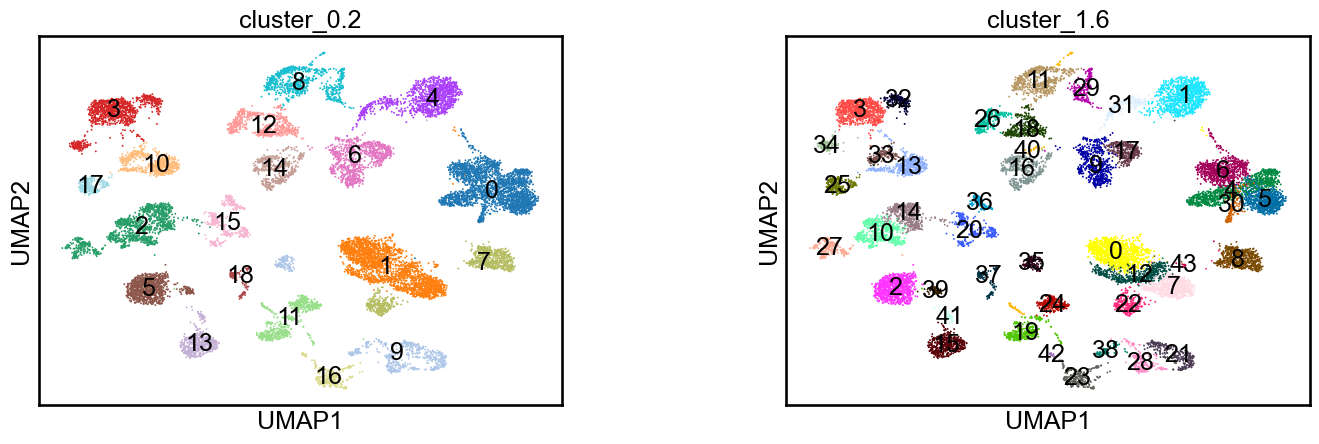

In [167]:
sc.pl.umap(adata_int, color=['cluster_0.2','cluster_1.6'], legend_loc='on data', ncols=2, wspace=0.3)

In [236]:
adata_sub = adata_int[adata_int.obs[celltype_col].isin(['beta'])]

The goal here is to find two cells in seemingly disparate clusters of beta cells
and see what path in the nearest neighbors graph connects them.

In [277]:
adata_sub[adata_sub.obs['cluster_0.2'] == '10'].obs.index

Index(['AZ_C10', 'AZ_A8', 'AZ_D6', 'AZ_H11', 'AZ_E7', 'AZ_G2', 'AZ_H6',
       'AZ_C4', 'AZ_F2', 'AZ_F1',
       ...
       'HP1526901T2D_G4', 'HP1526901T2D_P4', 'HP1526901T2D_I22',
       'HP1526901T2D_O8', 'HP1526901T2D_A5', 'HP1526901T2D_F18',
       'HP1526901T2D_D17', 'HP1526901T2D_A14', 'HP1526901T2D_B10',
       'HP1526901T2D_K7'],
      dtype='object', length=290)

In [278]:
adata_sub.obs.index.get_loc('AZ_H11')

867

In [173]:
G = nx.from_numpy_array(adata_sub.obsp['connectivities'], create_using=nx.DiGraph)

In [279]:
path = nx.shortest_path(G, source=1173, target=867, weight='weight')

In [280]:
cell_path = adata_sub.obs.iloc[path].index

In [281]:
indices = adata_int.obs_names.get_indexer(cell_path)
path_coords = adata_int.obsm['X_umap'][indices]

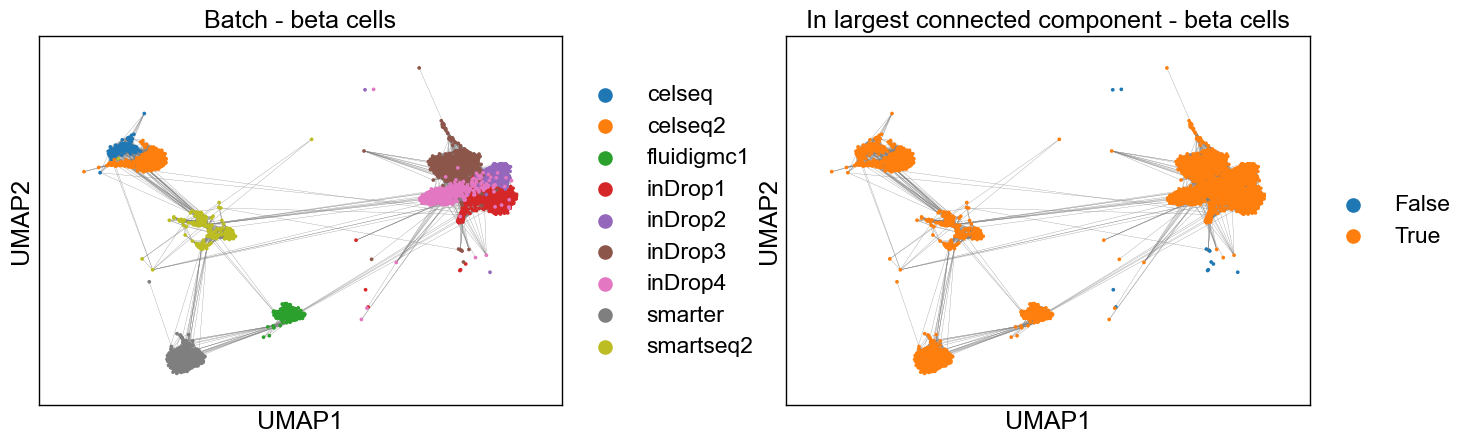

In [310]:
axes = sc.pl.umap(adata_sub, color=['tech', 'majority'], edges=True, edges_width=0.2, wspace=0.3, size=None,
           title=['Batch - beta cells', 'In largest connected component - beta cells'], show=False)
for ax in axes:
    for spine in ax.spines.values():
        spine.set_linewidth(1)
plt.show()

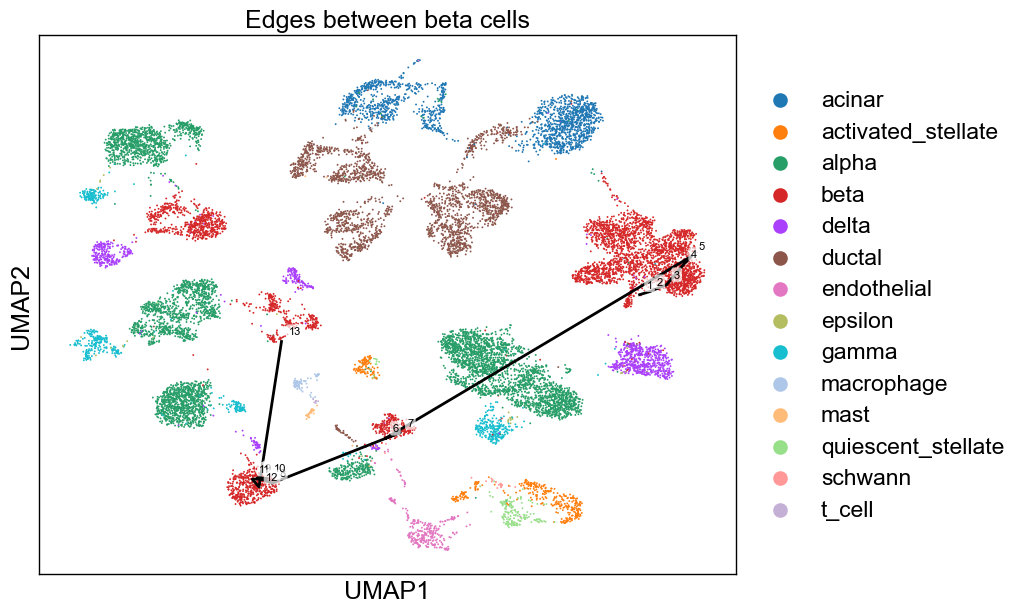

In [294]:
with plt.rc_context({'figure.figsize': (9, 7)}):
    ax = sc.pl.umap(adata_int, show=False, color=celltype_col, title='Edges between beta cells') # or your preferred coloring

    for spine in ax.spines.values():
        spine.set_linewidth(1)
    # Plot the path as a line
    # path_coords[:, 0] are X coordinates, path_coords[:, 1] are Y
    ax.plot(path_coords[:, 0], path_coords[:, 1], 
            color='black', 
            linewidth=2, 
            linestyle='-', 
            label='Trajectory',
            zorder=10) # zorder ensures the line stays on top of the dots

    # Optional: Add arrows to show direction
    for i, (x, y) in enumerate(path_coords):
        ax.annotate(
            str(i + 1),
            xy=(x, y),              # The actual cell location
            xytext=(5, 5),          # Offset in points (5 right, 5 up)
            textcoords='offset points', 
            fontsize=8,
            fontweight='bold',
            zorder=11,
            bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.7)
        )

    plt.show()

In [284]:
path_coords

array([[15.930514  ,  5.0634637 ],
       [16.334795  ,  5.241616  ],
       [17.021193  ,  5.6532426 ],
       [17.704554  ,  6.8407254 ],
       [18.030275  ,  7.328271  ],
       [ 5.6932006 , -3.3666153 ],
       [ 6.293364  , -3.0299764 ],
       [ 1.1335144 , -5.9935803 ],
       [ 0.54834664, -5.681697  ],
       [ 0.9262452 , -5.71883   ],
       [ 0.33077395, -5.766294  ],
       [ 0.6025722 , -6.221731  ],
       [ 1.5085177 ,  2.31331   ]], dtype=float32)

In [285]:
edges = [
    [[15.516072 ,  5.073435 ],
     [-3.8645468,  8.774377 ]],
    [[18.030275 ,  7.328271 ],
     [ 5.6932006, -3.3666153]],
    [[ 6.293364  , -3.0299764 ],
     [ 0.82872236, -5.8248887 ]],
    [[ 0.6025722 , -6.221731  ],
     [ 1.5085177 ,  2.31331   ]]
]

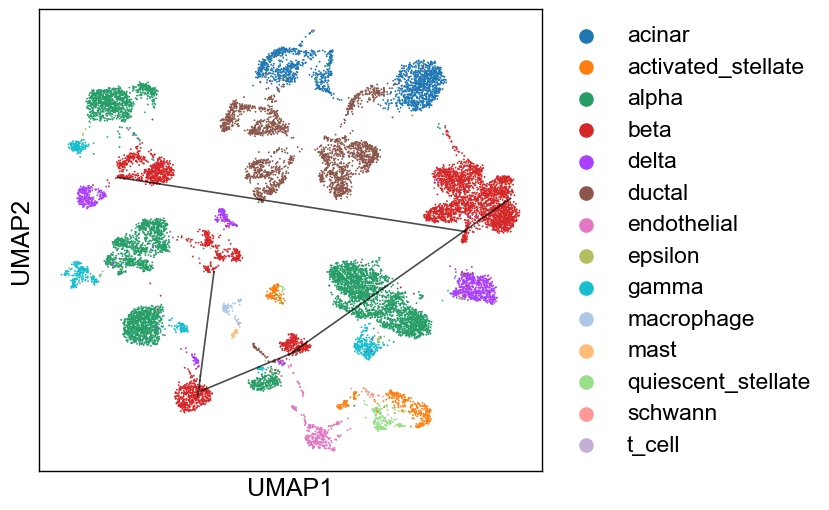

In [296]:
with plt.rc_context({'figure.figsize': (6.5, 6)}):
    ax = sc.pl.umap(adata_int, show=False, color=celltype_col, title='') # or your preferred coloring
    for spine in ax.spines.values():
        spine.set_linewidth(1)
    # Plot the path as a line
    # path_coords[:, 0] are X coordinates, path_coords[:, 1] are Y
    for e in edges:
        ax.plot([e[0][0], e[1][0]], [e[0][1], e[1][1]], color='black', lw=1.2, alpha=0.7, zorder=10)
    plt.show()

## Using a min-cut to determine number of edges needed to be removed to create disconnected components

In [212]:
from scipy.sparse.csgraph import maximum_flow
from scipy.sparse.csgraph import breadth_first_order

In [198]:
adj = adata_sub.obsp['connectivities']

In [201]:
adata_sub.obs_names[adata_sub.obs['cluster_0.2'] == '0']

Index(['human1_lib1.final_cell_0007', 'human1_lib1.final_cell_0015',
       'human1_lib1.final_cell_0017', 'human1_lib1.final_cell_0020',
       'human1_lib1.final_cell_0021', 'human1_lib1.final_cell_0024',
       'human1_lib1.final_cell_0027', 'human1_lib1.final_cell_0030',
       'human1_lib1.final_cell_0035', 'human1_lib1.final_cell_0037',
       ...
       'human4_lib3.final_cell_0687', 'human4_lib3.final_cell_0688',
       'human4_lib3.final_cell_0690', 'human4_lib3.final_cell_0691',
       'human4_lib3.final_cell_0692', 'human4_lib3.final_cell_0693',
       'human4_lib3.final_cell_0695', 'human4_lib3.final_cell_0696',
       'human4_lib3.final_cell_0699', 'human4_lib3.final_cell_0700'],
      dtype='object', length=2502)

In [203]:
adata_sub.obs_names.get_indexer(adata_sub.obs_names[adata_sub.obs['cluster_0.2'] == '0'])

array([1172, 1173, 1174, ..., 3694, 3695, 3696], shape=(2502,))

In [232]:
n_nodes = adj.shape[0]
set_A = adata_sub.obs_names.get_indexer(adata_sub.obs_names[adata_sub.obs['cluster_0.2'] == '0'])  # Indices for group A
set_B = adata_sub.obs_names.get_indexer(adata_sub.obs_names[adata_sub.obs['cluster_0.2'] == '11']) # Indices for group B

# 1. Expand the matrix by 2 to accommodate Super-Source (S) and Super-Sink (T)
# New index for S = n_nodes, New index for T = n_nodes + 1
capacity = scipy.sparse.csr_matrix((n_nodes + 2, n_nodes + 2))

# 2. Fill the original weights
# Note: You may need to use capacity = adj.tocsr() logic for efficiency
capacity[:n_nodes, :n_nodes] = adj
capacity[capacity > 0 ] = 1
capacity = capacity.astype(int)

# 3. Add infinite capacity edges from S to A and B to T
inf = 999999 # Use a value significantly larger than any sum of weights
for a in set_A:
    capacity[n_nodes, a] = inf
for b in set_B:
    capacity[b, n_nodes + 1] = inf

# 4. Compute Max Flow
# Use 'residual' to find which nodes belong to which side of the cut
res = maximum_flow(capacity, n_nodes, n_nodes + 1)

print(f"The total weight of the min-cut is: {res.flow_value}")

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scipy/sparse/_index.py:201: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


The total weight of the min-cut is: 20


In [220]:
len(set_A), len(set_B)

(2502, 258)

In [217]:
# 2. Calculate the Residual Capacity
# Residual = Original Capacity - Flow
residual_capacity = capacity - res.flow

# 3. Find reachable nodes from the source (S) in the residual graph
# A node is reachable if there is a path with capacity > 0
reachable_nodes = breadth_first_order(
    residual_capacity, 
    n_nodes, 
    directed=True, 
    return_predecessors=False
)

# 4. Define the partitions
# Nodes reachable from S are on the "Source Side"
source_side = [n for n in reachable_nodes if n < n_nodes]
# Nodes NOT reachable from S are on the "Sink Side"
sink_side = [n for n in range(n_nodes) if n not in reachable_nodes]

print(f"Nodes in Partition A side: {len(source_side)}")
print(f"Nodes in Partition B side: {len(sink_side)}")

Nodes in Partition A side: 2514
Nodes in Partition B side: 1655


In [218]:
source_set = set(reachable_nodes) # Includes nodes reachable from super-source
# (Note: reachable_nodes was calculated in the previous step)

# 2. Convert your original adjacency matrix to COOrdinate format 
# This makes it easy to iterate over existing edges (row, col, value)
adj_coo = adj.tocoo()

cut_edges = []
total_cut_weight = 0

for i, j, weight in zip(adj_coo.row, adj_coo.col, adj_coo.data):
    # An edge (i -> j) is part of the cut if:
    # i is in the source-reachable set AND j is NOT in the source-reachable set
    if i in source_set and j not in source_set:
        cut_edges.append((i, j))
        total_cut_weight += weight

print(f"Found {len(cut_edges)} edges crossing the partition.")
print(f"Verified Min-Cut Weight: {total_cut_weight}")
print(f"Example edges (indices): {cut_edges[:5]}")

Found 20 edges crossing the partition.
Verified Min-Cut Weight: 6.261102199554443
Example edges (indices): [(np.int32(1055), np.int32(1054)), (np.int32(1055), np.int32(1057)), (np.int32(1055), np.int32(1060)), (np.int32(1055), np.int32(1065)), (np.int32(1055), np.int32(1067))]


Plotting 20 edges...


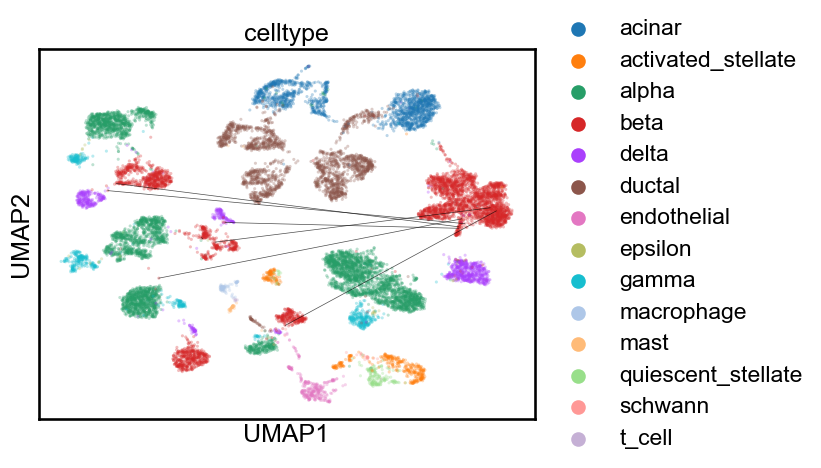

In [231]:
coords = adata_sub.obsm['X_umap']

# 2. Create the base UMAP plot using Scanpy
ax = sc.pl.umap(adata_int, show=False, color=celltype_col, alpha=0.3, size=20)

# 3. Iterate through the cut edges and draw them
print(f"Plotting {len(cut_edges)} edges...")

s = set()
for i, j in cut_edges:
    if i < coords.shape[0] and j < coords.shape[0] and i not in s and j not in s:
        x_values = [coords[i, 0], coords[j, 0]]
        y_values = [coords[i, 1], coords[j, 1]]
        s.add(i)
        s.add(j)
        ax.plot(x_values, y_values, color='black', lw=0.5, alpha=0.7, zorder=10)

In [373]:
adata_sub = adata_int[adata_int.obs[celltype_col].isin(['beta'])]
adj = adata_sub.obsp['connectivities']
n_nodes = adj.shape[0]

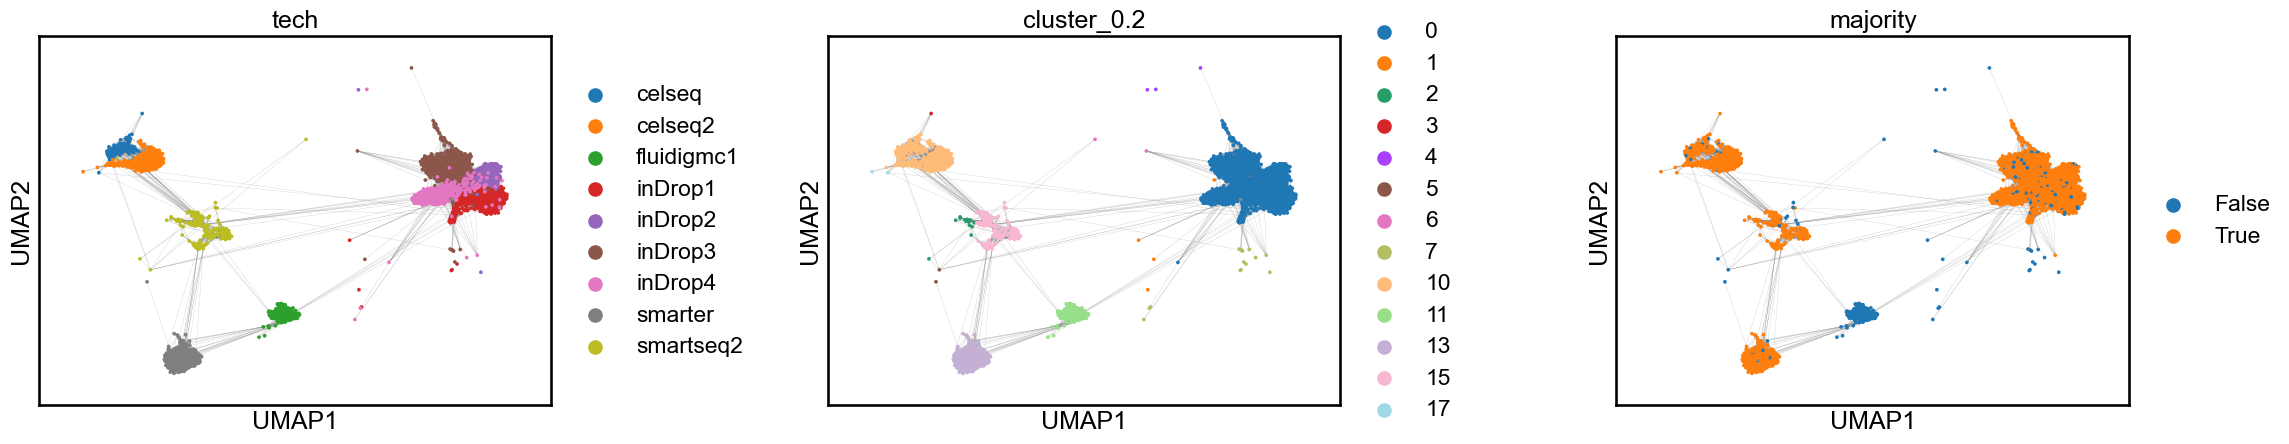

In [375]:
sc.pl.umap(adata_sub, color=['tech', 'cluster_0.2', 'majority'], wspace=0.4, edges=True)

In [376]:
set_A = adata_sub.obs_names.get_indexer(adata_sub.obs_names[adata_sub.obs['cluster_0.2'] == '0'])
set_B = adata_sub.obs_names.get_indexer(adata_sub.obs_names[adata_sub.obs['cluster_0.2'] == '10'])
set_C = adata_sub.obs_names.get_indexer(adata_sub.obs_names[adata_sub.obs['cluster_0.2'] == '15'])
set_D = adata_sub.obs_names.get_indexer(adata_sub.obs_names[adata_sub.obs['cluster_0.2'] == '11'])
set_E = adata_sub.obs_names.get_indexer(adata_sub.obs_names[adata_sub.obs['cluster_0.2'] == '13'])

partitions = [set_A, set_B, set_C, set_D, set_E]
# partitions = [set_A, set_B]
cut_weights = []

for i in range(len(partitions)):
    # Define Source as the current partition
    source_nodes = partitions[i]
    
    # Define Sink as the UNION of all other partitions
    sink_nodes = []
    for j in range(len(partitions)):
        if i != j:
            sink_nodes.extend(partitions[j])

    capacity = scipy.sparse.csr_matrix((n_nodes + 2, n_nodes + 2))

    capacity[:n_nodes, :n_nodes] = adj
    capacity[capacity > 0 ] = 1
    capacity = capacity.astype(int)

    inf = 999999 # Use a value significantly larger than any sum of weights
    for a in source_nodes:
        capacity[n_nodes, a] = inf
    for b in sink_nodes:
        capacity[b, n_nodes + 1] = inf

    # 4. Compute Max Flow
    # Use 'residual' to find which nodes belong to which side of the cut
    res = maximum_flow(capacity, n_nodes, n_nodes + 1)
    
    cut_weights.append(res.flow_value)
#     cut_edge_sets.append(identify_cut_edges(res))

# To get the Multiway Cut:
# Sort by weight and keep the 4 smallest cuts
total_weight = sum(sorted(cut_weights)[:-1])

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scipy/sparse/_index.py:201: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


In [380]:
adj

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 88942 stored elements and shape (4169, 4169)>

In [377]:
total_weight

np.int64(113)

In [381]:
113 / 88942

0.0012704908816981854

In [ ]:
min_edges_needed = {
    'acinar': 42,
    'activated_stellate': 8,
    'alpha': 62,
    'beta': 113,
    'delta': 10,
    'ductal': 2000162,
    'endothelial': np.nan,
    'gamma': 35,
    
}

## Comparing GC and GCD

GCD is the variation that uses the directed nearest neighbors graph `distances` rather than the undirected `connectivities`.

In [5]:
cvs = df_full[df_full['Integration'] != 'oneBigBlob-1'].pivot(index=['Dataset', 'Integration'], columns='Metric', values="Value").groupby('Dataset')[df_full.Metric.unique()].apply(
    lambda x: x.std() / x.mean().abs()
).reset_index()
mean_cv_per_metric = cvs[df_full.Metric.unique()].mean().sort_values(ascending=False)

In [6]:
x = cvs.set_index('Dataset')[df_full.Metric.unique()]['gc']
y = cvs.set_index('Dataset')[df_full.Metric.unique()]['gcd']

scipy.stats.wilcoxon(x, y, alternative='less')

WilcoxonResult(statistic=np.float64(0.0), pvalue=np.float64(7.450580596923828e-09))

/tmp/ipykernel_2949419/3678597479.py:36: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout() # This ensures the legend isn't cut off


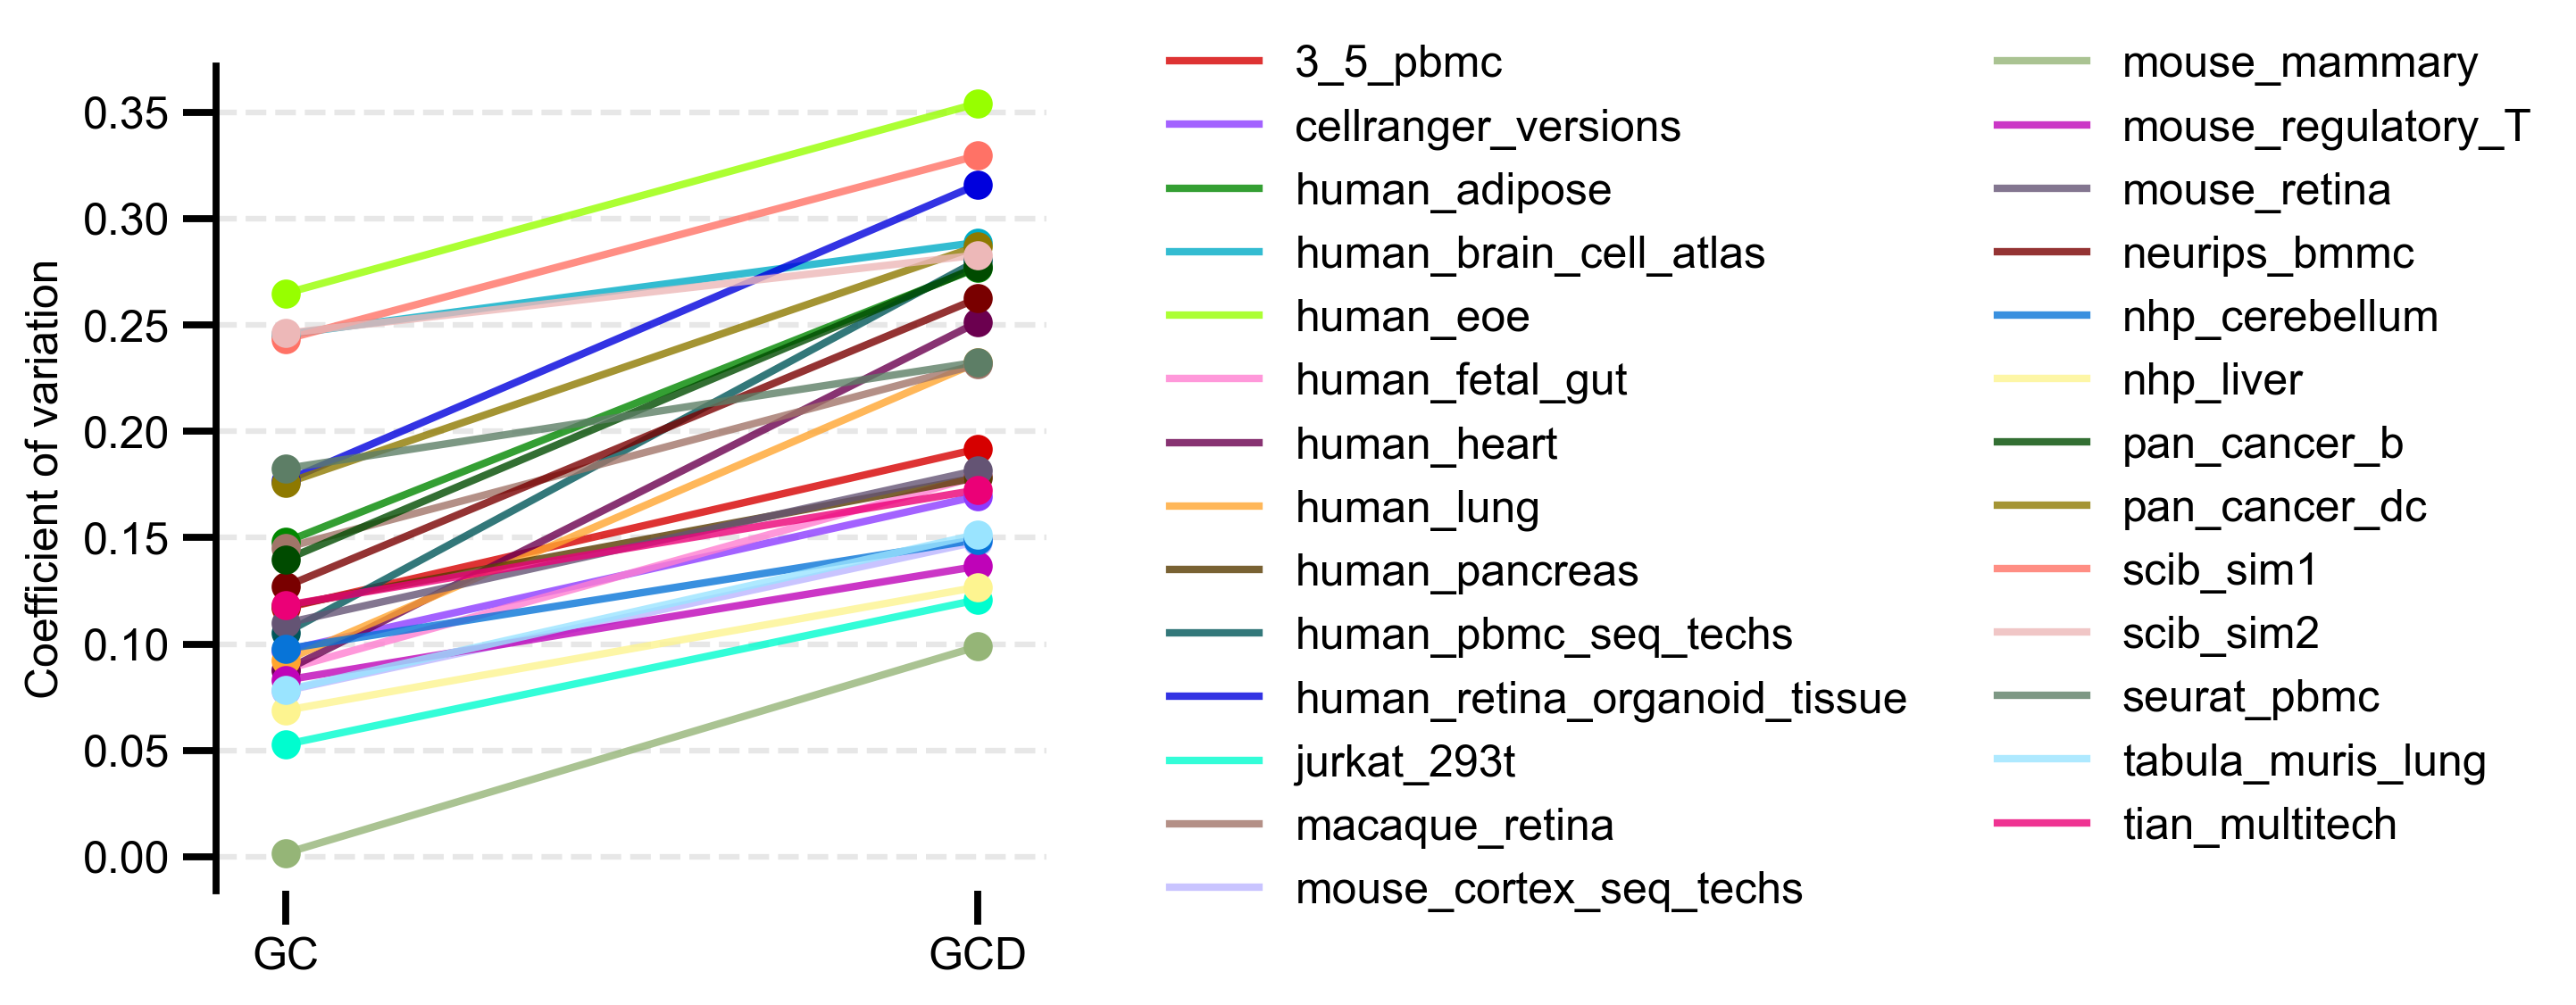

In [8]:
data = []
for i in x.index:
    data.append((i, x.loc[i], y.loc[i]))

palette = cc.glasbey
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = plt.subplots(figsize=(4, 4))

    # 2. Iterate and plot
    for i, (name, x_val, y_val) in enumerate(data):
        color = palette[i % len(palette)]

        # We assign 'label=name' once here so the legend can pick it up
        ax.plot([0, 1], [x_val, y_val], color=color, linewidth=2, alpha=0.8, label=name)
        ax.scatter([0, 1], [x_val, y_val], color=color, s=40, zorder=3)
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    # 3. Legend Configuration
    # 'bbox_to_anchor' moves the legend outside the plot area
    # 'ncol' helps if you have a long list of samples
    ax.legend(loc='center left', bbox_to_anchor=(1.1, 0.5), title="", frameon=False, ncol=2, fontsize=12)

    # 4. Styling
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['GC', 'GCD'], fontsize=12, fontweight='bold')
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylabel("Coefficient of variation", fontsize=12)

    # Clean aesthetics
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', alpha=0.3)

    # plt.title('Coefficient of\nvariation', fontsize=14, loc='center', pad=20)
    plt.tight_layout() # This ensures the legend isn't cut off
    plt.show()

## Annotatability

We use Annotatability (Karin et al., 2024) to investigate the nature of the cells outside the largest connected component.

In [395]:
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/yinian/libraries/Annotatability/')
import pickle

In [396]:
import torch
from Annotatability import models, metrics

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [398]:
adata.X = adata.X.astype(np.float32).toarray()

In [435]:
epoch_num = 100

In [436]:
prob_list = models.follow_training_dyn_neural_net(adata, label_key='celltype',iterNum=epoch_num, device=device)

/ubc/cs/research/beaver/projects/yinian/libraries/Annotatability/Annotatability/models.py:341: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if adata.obs[label_key][i] == t:


[1,     2] loss: 0.526
[1,    12] loss: 2.612
[1,    22] loss: 2.542
[1,    32] loss: 2.452
[1,    42] loss: 2.343
[1,    52] loss: 2.220
[1,    62] loss: 2.080
[2,     2] loss: 0.388
[2,    12] loss: 1.821
[2,    22] loss: 1.622
[2,    32] loss: 1.422
[2,    42] loss: 1.240
[2,    52] loss: 1.050
[2,    62] loss: 0.909
[3,     2] loss: 0.162
[3,    12] loss: 0.746
[3,    22] loss: 0.662
[3,    32] loss: 0.585
[3,    42] loss: 0.531
[3,    52] loss: 0.488
[3,    62] loss: 0.455
[4,     2] loss: 0.084
[4,    12] loss: 0.410
[4,    22] loss: 0.358
[4,    32] loss: 0.342
[4,    42] loss: 0.320
[4,    52] loss: 0.299
[4,    62] loss: 0.272
[5,     2] loss: 0.051
[5,    12] loss: 0.249
[5,    22] loss: 0.214
[5,    32] loss: 0.227
[5,    42] loss: 0.198
[5,    52] loss: 0.187
[5,    62] loss: 0.169
[6,     2] loss: 0.033
[6,    12] loss: 0.167
[6,    22] loss: 0.161
[6,    32] loss: 0.150
[6,    42] loss: 0.155
[6,    52] loss: 0.151
[6,    62] loss: 0.131
[7,     2] loss: 0.028
[7,    12] 

[50,    12] loss: 0.013
[50,    22] loss: 0.011
[50,    32] loss: 0.010
[50,    42] loss: 0.013
[50,    52] loss: 0.016
[50,    62] loss: 0.018
[51,     2] loss: 0.004
[51,    12] loss: 0.010
[51,    22] loss: 0.014
[51,    32] loss: 0.026
[51,    42] loss: 0.015
[51,    52] loss: 0.013
[51,    62] loss: 0.011
[52,     2] loss: 0.006
[52,    12] loss: 0.018
[52,    22] loss: 0.014
[52,    32] loss: 0.010
[52,    42] loss: 0.012
[52,    52] loss: 0.012
[52,    62] loss: 0.009
[53,     2] loss: 0.002
[53,    12] loss: 0.013
[53,    22] loss: 0.013
[53,    32] loss: 0.013
[53,    42] loss: 0.011
[53,    52] loss: 0.009
[53,    62] loss: 0.009
[54,     2] loss: 0.004
[54,    12] loss: 0.014
[54,    22] loss: 0.014
[54,    32] loss: 0.014
[54,    42] loss: 0.010
[54,    52] loss: 0.013
[54,    62] loss: 0.010
[55,     2] loss: 0.002
[55,    12] loss: 0.011
[55,    22] loss: 0.009
[55,    32] loss: 0.009
[55,    42] loss: 0.011
[55,    52] loss: 0.010
[55,    62] loss: 0.010
[56,     2] loss

[99,     2] loss: 0.001
[99,    12] loss: 0.006
[99,    22] loss: 0.007
[99,    32] loss: 0.005
[99,    42] loss: 0.005
[99,    52] loss: 0.004
[99,    62] loss: 0.006
[100,     2] loss: 0.001
[100,    12] loss: 0.005
[100,    22] loss: 0.005
[100,    32] loss: 0.005
[100,    42] loss: 0.006
[100,    52] loss: 0.009
[100,    62] loss: 0.005


In [437]:
all_conf , all_var = models.probability_list_to_confidence_and_var(prob_list, n_obs= adata.n_obs, epoch_num=epoch_num)

/ubc/cs/research/beaver/projects/yinian/libraries/Annotatability/Annotatability/models.py:378: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  confidence += (prob_list[i])
/ubc/cs/research/beaver/projects/yinian/libraries/Annotatability/Annotatability/models.py:382: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  variability += torch.square(confidence - (prob_list[i]))


In [438]:
adata.obs["var"] = list(all_var.detach().numpy())
adata.obs["conf"] = list(all_conf.detach().numpy())

In [439]:
conf, var = models.find_cutoff_paramter(adata,'celltype', device=device, probability=0.05,percentile=90, epoch_num=epoch_num)

/ubc/cs/research/beaver/projects/yinian/libraries/Annotatability/Annotatability/models.py:341: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if adata.obs[label_key][i] == t:


[1,     2] loss: 0.528
[1,    12] loss: 2.627
[1,    22] loss: 2.592
[1,    32] loss: 2.545
[1,    42] loss: 2.495
[1,    52] loss: 2.436
[1,    62] loss: 2.376
[2,     2] loss: 0.464
[2,    12] loss: 2.275
[2,    22] loss: 2.187
[2,    32] loss: 2.119
[2,    42] loss: 2.001
[2,    52] loss: 1.912
[2,    62] loss: 1.822
[3,     2] loss: 0.356
[3,    12] loss: 1.774
[3,    22] loss: 1.678
[3,    32] loss: 1.660
[3,    42] loss: 1.575
[3,    52] loss: 1.537
[3,    62] loss: 1.503
[4,     2] loss: 0.287
[4,    12] loss: 1.459
[4,    22] loss: 1.434
[4,    32] loss: 1.355
[4,    42] loss: 1.391
[4,    52] loss: 1.340
[4,    62] loss: 1.272
[5,     2] loss: 0.260
[5,    12] loss: 1.217
[5,    22] loss: 1.221
[5,    32] loss: 1.209
[5,    42] loss: 1.176
[5,    52] loss: 1.139
[5,    62] loss: 1.105
[6,     2] loss: 0.229
[6,    12] loss: 1.125
[6,    22] loss: 1.069
[6,    32] loss: 1.054
[6,    42] loss: 1.025
[6,    52] loss: 1.036
[6,    62] loss: 0.980
[7,     2] loss: 0.195
[7,    12] 

[50,    12] loss: 0.055
[50,    22] loss: 0.060
[50,    32] loss: 0.059
[50,    42] loss: 0.051
[50,    52] loss: 0.050
[50,    62] loss: 0.065
[51,     2] loss: 0.010
[51,    12] loss: 0.063
[51,    22] loss: 0.060
[51,    32] loss: 0.054
[51,    42] loss: 0.059
[51,    52] loss: 0.050
[51,    62] loss: 0.054
[52,     2] loss: 0.014
[52,    12] loss: 0.059
[52,    22] loss: 0.062
[52,    32] loss: 0.054
[52,    42] loss: 0.055
[52,    52] loss: 0.049
[52,    62] loss: 0.051
[53,     2] loss: 0.011
[53,    12] loss: 0.064
[53,    22] loss: 0.049
[53,    32] loss: 0.057
[53,    42] loss: 0.059
[53,    52] loss: 0.045
[53,    62] loss: 0.055
[54,     2] loss: 0.008
[54,    12] loss: 0.050
[54,    22] loss: 0.057
[54,    32] loss: 0.062
[54,    42] loss: 0.057
[54,    52] loss: 0.054
[54,    62] loss: 0.044
[55,     2] loss: 0.007
[55,    12] loss: 0.045
[55,    22] loss: 0.042
[55,    32] loss: 0.043
[55,    42] loss: 0.050
[55,    52] loss: 0.046
[55,    62] loss: 0.048
[56,     2] loss

[99,     2] loss: 0.003
[99,    12] loss: 0.017
[99,    22] loss: 0.020
[99,    32] loss: 0.019
[99,    42] loss: 0.016
[99,    52] loss: 0.014
[99,    62] loss: 0.019
[100,     2] loss: 0.004
[100,    12] loss: 0.015
[100,    22] loss: 0.015
[100,    32] loss: 0.015
[100,    42] loss: 0.021
[100,    52] loss: 0.017
[100,    62] loss: 0.013


/ubc/cs/research/beaver/projects/yinian/libraries/Annotatability/Annotatability/models.py:378: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  confidence += (prob_list[i])
/ubc/cs/research/beaver/projects/yinian/libraries/Annotatability/Annotatability/models.py:382: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  variability += torch.square(confidence - (prob_list[i]))


In [440]:
adata.obs['conf_binaries'] = pd.Categorical((adata.obs['conf'] > conf) |  (adata.obs['var'] > var))
adata.obs['conf_correct'] = pd.Categorical((adata.obs['conf'] > 0.95) &  (adata.obs['var'] < 0.2))

In [441]:
corr_classified_list =[]
for i in range(adata.n_obs):
    if adata.obs['conf_binaries'][i]==False:
        corr_classified_list.append('Erroneously annotated')
    else:
        if adata.obs['conf_correct'][i]==False:
            corr_classified_list.append('Ambiguous annotation')
        else:
            corr_classified_list.append('Correctly annotated')

adata.obs['Annotation']=corr_classified_list

/tmp/ipykernel_3475038/2203169834.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if adata.obs['conf_binaries'][i]==False:
/tmp/ipykernel_3475038/2203169834.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if adata.obs['conf_correct'][i]==False:


In [442]:
adata.obs['Confidence']=adata.obs['conf']
adata.obs['Variability']=adata.obs['var']

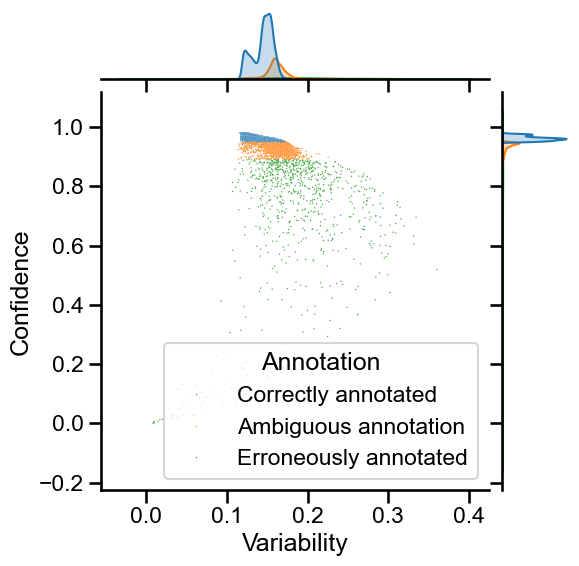

In [443]:
fig = sns.jointplot(data=adata.obs, x="Variability", y="Confidence",hue='Annotation',s=1)
plt.show(fig)

In [444]:
adata.obs['Annotation'].value_counts()

Annotation
Correctly annotated      12327
Ambiguous annotation      3210
Erroneously annotated      845
Name: count, dtype: int64

In [449]:
adata_int.obs['conf_binaries'] = adata.obs['conf_binaries']
adata_int.obs['conf_correct'] = adata.obs['conf_correct']
adata_int.obs['Annotation'] = adata.obs['Annotation']

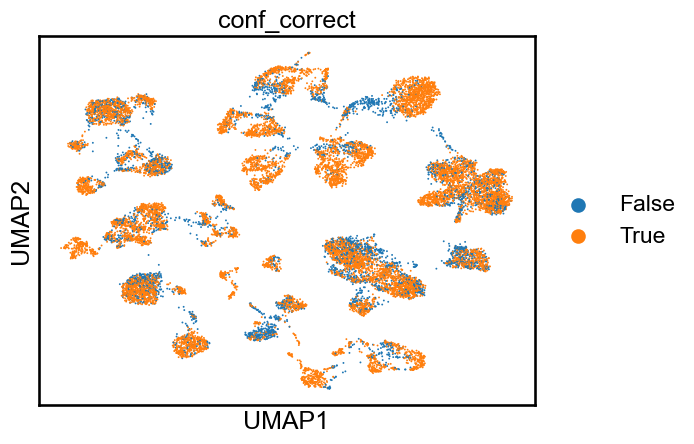

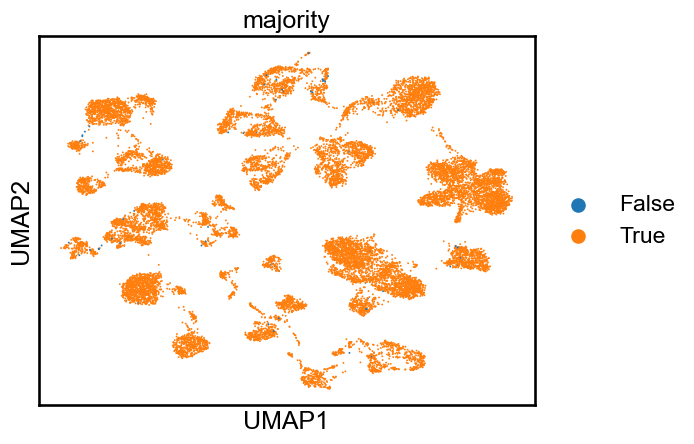

In [446]:
sc.pl.umap(adata_int,color=['conf_correct'])
sc.pl.umap(adata_int,color=['majority'])

In [450]:
adata_int.obs[['majority', 'Annotation']].value_counts()

majority  Annotation           
True      Correctly annotated      12315
          Ambiguous annotation      3200
          Erroneously annotated      793
False     Erroneously annotated       52
          Correctly annotated         12
          Ambiguous annotation        10
Name: count, dtype: int64

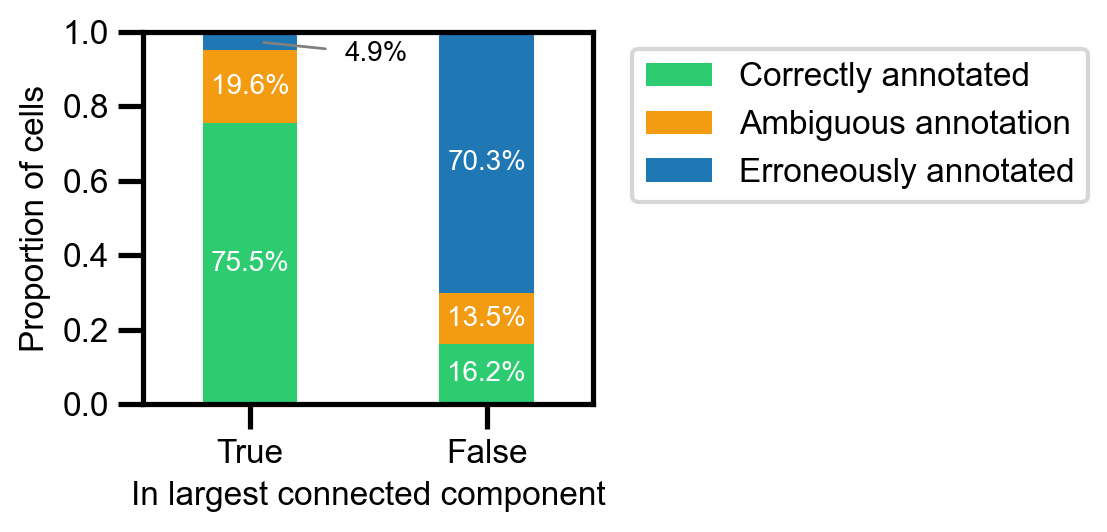

In [488]:
data = {
    (True, 'Correctly annotated'): 12315, (True, 'Ambiguous annotation'): 3200, (True, 'Erroneously annotated'): 793,
    (False, 'Erroneously annotated'): 52, (False, 'Correctly annotated'): 12, (False, 'Ambiguous annotation'): 10
}

series = pd.Series(data)
series.index.names = ['Majority', 'Annotation']
df = series.unstack(level='Annotation').fillna(0)

cols_order = ['Correctly annotated', 'Ambiguous annotation', 'Erroneously annotated']
df = df[cols_order]
df_norm = df.div(df.sum(axis=1), axis=0)

colors = ['#2ecc71', '#f39c12', '#1f77b4']
df_norm.index = df_norm.index.map({True: 'True', False: 'False'})

with plt.rc_context({'figure.dpi': 200}):
    ax = df_norm.loc[['True', 'False']].plot(
        kind='bar',
        stacked=True,
        figsize=(6, 3),
        color=colors,
        width=0.4
    )
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)

    for p in ax.patches:
        height = p.get_height()
        if height == 0: continue
        
        x_center = p.get_x() + p.get_width() / 2
        y_center = p.get_y() + height / 2
        
        if height < 0.06:
            ax.annotate(
                f'{height:.1%}',
                xy=(x_center, y_center),
                xytext=(x_center + 0.4, y_center),
                arrowprops=dict(
                    arrowstyle='-',
                    color='gray',
                    linewidth=1,
                    shrinkA=5, shrinkB=5
                ),
                va='top',
                ha='left',
                fontsize=10,
                color='black'
            )
        else:
            ax.text(
                x_center, y_center, f'{height:.1%}', 
                ha='center', va='center', 
                color='white', fontweight='bold', fontsize=10
            )
    # Formatting
    plt.ylabel('Proportion of cells', fontsize=12)
    plt.xlabel('In largest connected component', fontsize=12)
    plt.xticks(ticks=[0, 1], labels=['True', 'False'], rotation=0)
    plt.ylim(0, 1)
    plt.legend( bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=12)

    plt.tight_layout()
    plt.show()